# Data Understanding, Preprocessing and Feature Engineering

Loads the raw SCADA file, explores it, checks data quality, engineers the features and saves the model-ready tables used by notebooks 02–04.

**Input:** `wind_turbine.csv` · **Outputs:** `out/01_preprocessing/` and `figures/fig2-*`, `fig3-*`, `fig4-*` (named after the report figure they produce).

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("../wind_turbine.csv")
OUT_DIR = Path("../out/01_preprocessing")
FIG_DIR = Path("../figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

INTERVAL_H = 10 / 60        # each record is a 10-minute average
WS_BIN = 0.5                # m/s, IEC 61400-12-1 power-curve bin width
DIR_SECTOR = 30             # degrees
CUTIN_BUFFER = 0.5          # m/s added to the cut-in speed to define the operating region
UNDERPERF_RATIO = 0.80      # power ratio below this is "underperforming"
RATIO_CLIP = (0.0, 1.5)

STATE_COLORS = {"near_curve": "#2a78d6", "underperforming": "#eda100",
                "zero_output": "#eb6834", "below_operating_range": "#9a9a92"}
INK, GRID = "#3d3d3a", "#e4e3dd"
REPORT_STYLE = {"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                "axes.spines.top": False, "axes.spines.right": False,
                "axes.edgecolor": INK, "axes.labelcolor": INK,
                "xtick.color": INK, "ytick.color": INK,
                "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6}
pd.set_option("display.float_format", "{:,.3f}".format)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=200)
    plt.show()

## A. Data understanding

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Shape:", raw.shape)
print(raw.dtypes)
raw.head()

Shape: (50530, 5)
Date/Time                            str
LV ActivePower (kW)              float64
Wind Speed (m/s)                 float64
Theoretical_Power_Curve (KWh)    float64
Wind Direction (°)               float64
dtype: object


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.048,5.311,416.329,259.995
1,01 01 2018 00:10,453.769,5.672,519.918,268.641
2,01 01 2018 00:20,306.377,5.216,390.900,272.565
3,01 01 2018 00:30,419.646,5.660,516.128,271.258
4,01 01 2018 00:40,380.651,5.578,491.703,265.674


In [3]:
df = raw.rename(columns={
    "Date/Time": "timestamp",
    "LV ActivePower (kW)": "power_kw",
    "Wind Speed (m/s)": "wind_speed",
    "Theoretical_Power_Curve (KWh)": "theo_power_kw",
    "Wind Direction (°)": "wind_dir",
})
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%d %m %Y %H:%M", errors="coerce")
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
power_kw,"50,530.000","1,307.684","1,312.459",-2.471,50.678,825.838,"2,482.508","3,618.733"
wind_speed,"50,530.000",7.558,4.227,0.000,4.201,7.105,10.300,25.206
theo_power_kw,"50,530.000","1,492.175","1,368.018",0.000,161.328,"1,063.776","2,964.972","3,600.000"
wind_dir,"50,530.000",123.688,93.444,0.000,49.315,73.713,201.697,359.998


**Unit note.** The theoretical column is labelled *KWh* in the file, but its maximum is exactly 3,600, the turbine's rated power in **kW**. It is the expected average power over each 10-minute interval, so it is treated as kW and converted to energy with × 1/6 h, like actual power.

### A1. Exploratory visualisations (report Figures 2.1–2.5)

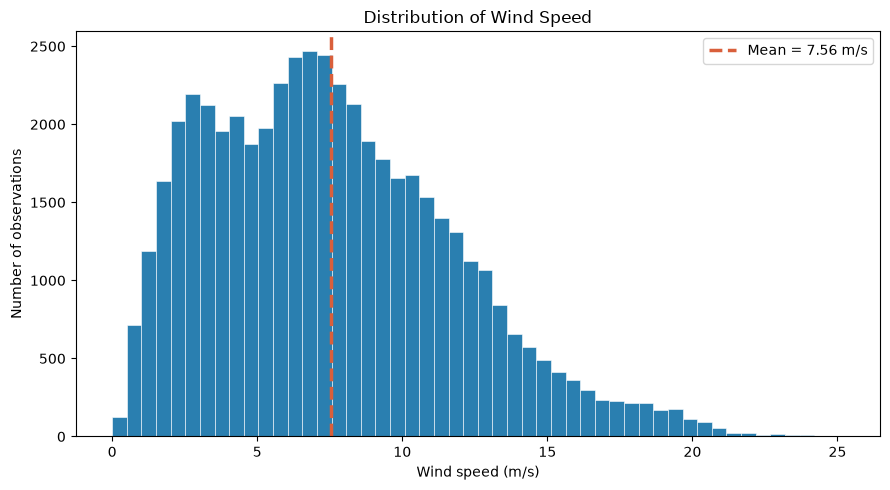

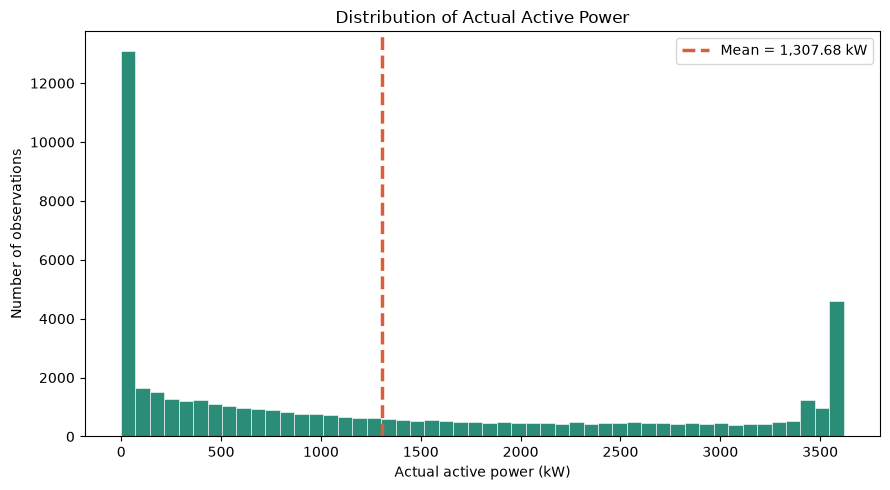

In [4]:
def histogram(series, color, xlabel, title, mean_label, name):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(series, bins=50, color=color, edgecolor="white", linewidth=0.4)
    ax.axvline(series.mean(), color="#d95f3b", lw=2.5, ls="--", label=mean_label)
    ax.set(xlabel=xlabel, ylabel="Number of observations", title=title)
    ax.legend()
    save_fig(fig, name)


histogram(df.wind_speed, "#2a7fb0", "Wind speed (m/s)", "Distribution of Wind Speed",
          f"Mean = {df.wind_speed.mean():.2f} m/s", "fig2-1_wind_speed_distribution.png")
histogram(df.power_kw, "#2b8c78", "Actual active power (kW)", "Distribution of Actual Active Power",
          f"Mean = {df.power_kw.mean():,.2f} kW", "fig2-2_active_power_distribution.png")

Pearson r, wind speed vs actual power:        0.913
Pearson r, theoretical power vs actual power: 0.950


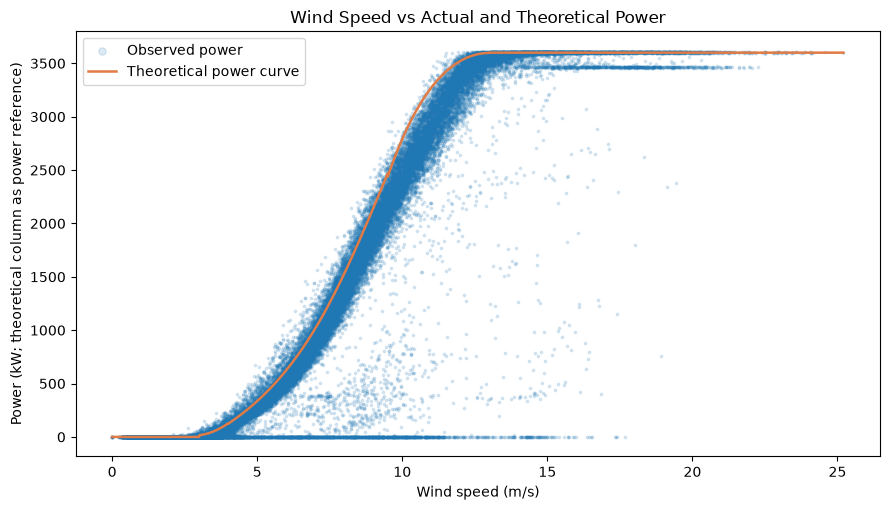

In [5]:
corr = df[["wind_speed", "theo_power_kw"]].corrwith(df.power_kw)
print(f"Pearson r, wind speed vs actual power:        {corr['wind_speed']:.3f}")
print(f"Pearson r, theoretical power vs actual power: {corr['theo_power_kw']:.3f}")

curve = df.sort_values("wind_speed")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(df.wind_speed, df.power_kw, s=3, alpha=0.15, label="Observed power", rasterized=True)
ax.plot(curve.wind_speed, curve.theo_power_kw, color="#e07b45", lw=1.8, label="Theoretical power curve")
ax.set(xlabel="Wind speed (m/s)", ylabel="Power (kW; theoretical column as power reference)",
       title="Wind Speed vs Actual and Theoretical Power")
ax.legend(loc="upper left", markerscale=3)
save_fig(fig, "fig2-3_power_curve.png")

timestamp
Jan   1,323.200
Feb   1,503.400
Mar   1,952.400
Apr     824.400
May     836.900
Jun     995.500
Jul     477.000
Aug   1,978.200
Sep   1,429.500
Oct   1,408.300
Nov   1,886.700
Dec   1,176.800


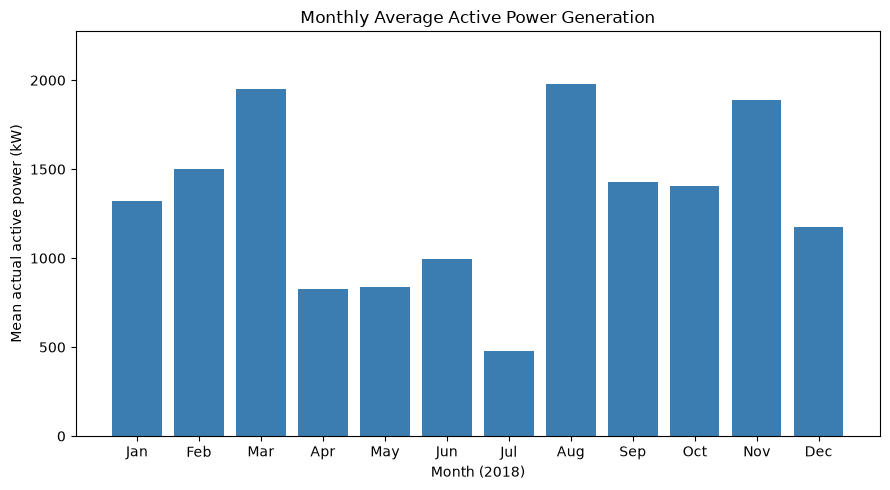

In [6]:
monthly_mean = df.groupby(df.timestamp.dt.month).power_kw.mean()
monthly_mean.index = pd.to_datetime(monthly_mean.index.astype(str), format="%m").strftime("%b")
print(monthly_mean.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(monthly_mean.index, monthly_mean, color="#3b7db0")
ax.set(xlabel="Month (2018)", ylabel="Mean actual active power (kW)", ylim=(0, monthly_mean.max() * 1.15),
       title="Monthly Average Active Power Generation")
save_fig(fig, "fig2-4_monthly_mean_power.png")

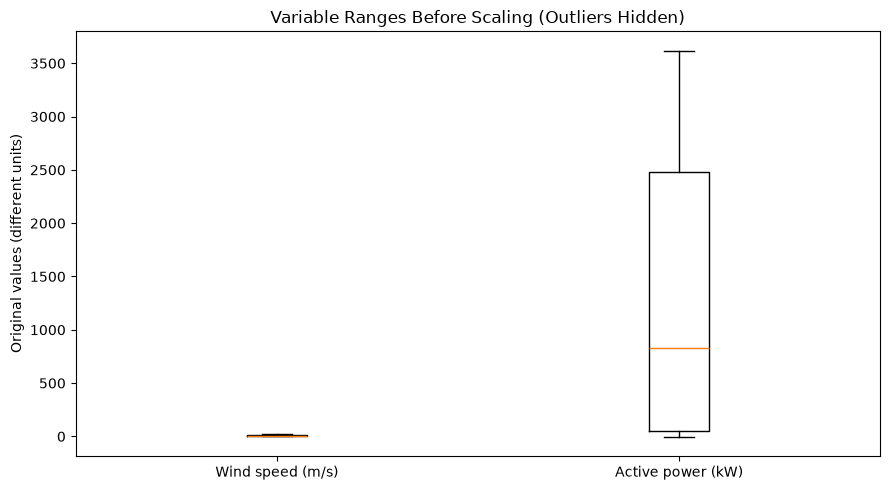

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([df.wind_speed, df.power_kw], showfliers=False)
ax.set_xticks([1, 2], ["Wind speed (m/s)", "Active power (kW)"])
ax.set(ylabel="Original values (different units)", title="Variable Ranges Before Scaling (Outliers Hidden)")
save_fig(fig, "fig2-5_feature_scales.png")

Wind speed and power sit on very different scales, so distance-based clustering needs standardised inputs. The points on zero at high wind and the scatter under the curve in Figure 2.3 are the abnormal states the project must **keep**.

## B. Data preprocessing

### B1. Timestamps, missing values and duplicates

In [8]:
plt.rcParams.update(REPORT_STYLE)

n_bad_ts = int(df.timestamp.isna().sum())
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
null_counts = df.isna().sum()
n_exact_dup = int(df.duplicated().sum())
n_ts_dup = int(df.timestamp.duplicated().sum())

df = df.drop_duplicates()
if df.timestamp.duplicated().any():
    df = df.groupby("timestamp", as_index=False).mean(numeric_only=True)

print("Unparseable timestamps:", n_bad_ts)
print("Range:", df.timestamp.min(), "->", df.timestamp.max())
print("Null values:", int(null_counts.sum()))
print("Exact duplicate rows:", n_exact_dup, "| duplicate timestamps:", n_ts_dup)

Unparseable timestamps: 0
Range: 2018-01-01 00:00:00 -> 2018-12-31 23:50:00
Null values: 0
Exact duplicate rows: 0 | duplicate timestamps: 0


### B2. Missing 10-minute intervals

No nulls does not mean no missing data: some 10-minute slots are simply absent. They are **not imputed**, because inventing power readings would invent energy and bias the loss estimate. The gaps are recorded in `gap_before_min` instead.

In [9]:
full_grid = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="10min")
n_missing_slots = len(full_grid) - len(df)

df["gap_before_min"] = df.timestamp.diff().dt.total_seconds().div(60).fillna(10)
gaps = df.loc[df.gap_before_min > 10, ["timestamp", "gap_before_min"]].copy()
gaps["missing_slots"] = (gaps.gap_before_min / 10 - 1).astype(int)

print(f"Expected slots: {len(full_grid):,} | recorded: {len(df):,} | "
      f"missing: {n_missing_slots:,} ({n_missing_slots / len(full_grid):.1%}) across {len(gaps)} gaps")
print("\nLargest gaps:")
print(gaps.nlargest(5, "missing_slots").to_string(index=False))

coverage = pd.DataFrame({
    "expected": pd.Series(full_grid.month).value_counts().sort_index(),
    "recorded": df.timestamp.dt.month.value_counts().sort_index(),
})
coverage["coverage_%"] = 100 * coverage.recorded / coverage.expected
coverage

Expected slots: 52,560 | recorded: 50,530 | missing: 2,030 (3.9%) across 32 gaps

Largest gaps:
          timestamp  gap_before_min  missing_slots
2018-01-30 14:40:00       6,260.000            625
2018-10-02 16:30:00       5,470.000            546
2018-11-14 12:00:00       5,210.000            520
2018-10-03 06:30:00         740.000             73
2018-10-03 14:10:00         450.000             44


,expected,recorded,coverage_%
1,4464,3817,85.506
2,4032,4032,100.000
3,4464,4463,99.978
4,4320,4305,99.653
5,4464,4449,99.664
6,4320,4245,98.264
7,4464,4464,100.000
8,4464,4425,99.126
9,4320,4000,92.593
10,4464,4083,91.465


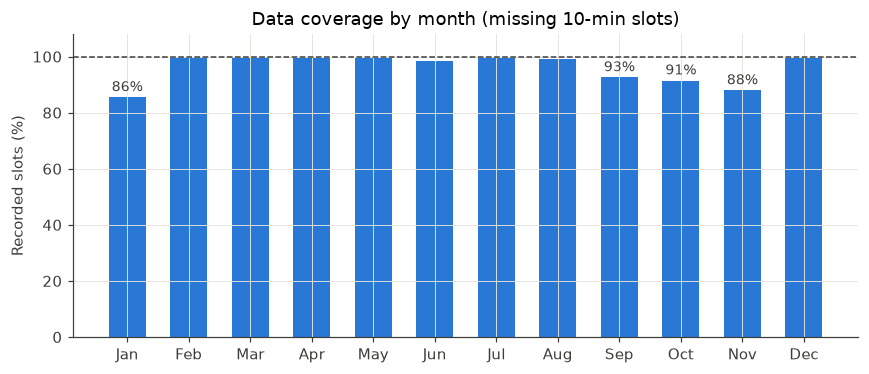

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
months = pd.to_datetime(coverage.index.astype(str), format="%m").strftime("%b")
ax.bar(months, coverage["coverage_%"], color="#2a78d6", width=0.6)
ax.axhline(100, color=INK, lw=1, ls="--")
for x, v in zip(months, coverage["coverage_%"]):
    if v < 95:
        ax.text(x, v + 1, f"{v:.0f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set(ylim=(0, 108), ylabel="Recorded slots (%)", title="Data coverage by month (missing 10-min slots)")
save_fig(fig, "fig3-1_coverage_by_month.png")

### B3. Range validation — remove only physically impossible values

| Rule | Why |
|---|---|
| wind speed < 0 or > 40 m/s | negative speed is impossible; > 40 m/s is a sensor fault for this site |
| wind direction outside 0–360° | not a valid bearing |
| power > 110 % of rated | the turbine cannot exceed its rating by this much |
| theoretical power outside 0–rated | the manufacturer curve cannot do this |

Small **negative power** is kept: it is the turbine drawing grid power while idle, which is real information about shutdown states.

In [11]:
RATED_KW = df.theo_power_kw.max()
impossible = (
    ~df.wind_speed.between(0, 40)
    | ~df.wind_dir.between(0, 360)
    | (df.power_kw > 1.10 * RATED_KW)
    | ~df.theo_power_kw.between(0, RATED_KW)
)
n_impossible = int(impossible.sum())
df = df.loc[~impossible].reset_index(drop=True)
df["wind_dir"] = df.wind_dir % 360

n_neg_power = int((df.power_kw < 0).sum())
print("Rated power (kW):", RATED_KW)
print("Impossible records removed:", n_impossible)
print(f"Negative-power records kept: {n_neg_power}, min = {df.power_kw.min():.2f} kW")

Rated power (kW): 3600.0
Impossible records removed: 0
Negative-power records kept: 57, min = -2.47 kW


**Check on the negative readings.** Each one is inspected with its wind speed and its neighbouring records to confirm it is an isolated idle reading and not a sensor fault.

In [12]:
negative = df.power_kw < 0
run_id = (~negative | (df.gap_before_min > 10)).cumsum()
run_lengths = df[negative].groupby(run_id[negative]).size()
neighbour_kw = pd.concat([df.power_kw.shift(1)[negative], df.power_kw.shift(-1)[negative]])

print(f"Negative readings: {negative.sum()} in {len(run_lengths)} separate runs "
      f"(longest run: {run_lengths.max()} record)")
print(f"Power: {df.loc[negative, 'power_kw'].min():.2f} to {df.loc[negative, 'power_kw'].max():.4f} kW")
print(f"Wind speed: median {df.loc[negative, 'wind_speed'].median():.1f} m/s, "
      f"max {df.loc[negative, 'wind_speed'].max():.1f} m/s")
print(f"Power in the record before/after: median {neighbour_kw.median():.1f} kW, max {neighbour_kw.max():.0f} kW")

Negative readings: 57 in 57 separate runs (longest run: 1 record)
Power: -2.47 to -0.0005 kW
Wind speed: median 2.7 m/s, max 4.6 m/s
Power in the record before/after: median 4.6 kW, max 134 kW


### B4. Data quality summary

In [13]:
dq = pd.DataFrame([
    ("Raw records", f"{len(raw):,}", "As downloaded"),
    ("Unparseable timestamps", n_bad_ts, "Format DD MM YYYY HH:MM"),
    ("Null values (all columns)", int(null_counts.sum()), "No imputation needed"),
    ("Exact duplicate rows", n_exact_dup, "Dropped if present"),
    ("Duplicate timestamps", n_ts_dup, "Averaged if present"),
    ("Missing 10-min slots", f"{n_missing_slots:,} ({n_missing_slots / len(full_grid):.1%})",
     "Not imputed; flagged via gap_before_min"),
    ("Timestamp gaps", len(gaps), "Documented"),
    ("Largest single gap",
     f"{gaps.missing_slots.max():,} slots (~{gaps.gap_before_min.max() / 60 / 24:.1f} days)",
     "Reported as limitation"),
    ("Impossible values removed", n_impossible, "Range rules in B3"),
    ("Negative power records", n_neg_power, "Kept — idle/shutdown signal"),
    ("Final records", f"{len(df):,}", "Used for all later steps"),
], columns=["Check", "Result", "Action"])
dq

,Check,Result,Action
0,Raw records,"50,530",As downloaded
1,Unparseable timestamps,0,Format DD MM YYYY HH:MM
2,Null values (all columns),0,No imputation needed
3,Exact duplicate rows,0,Dropped if present
4,Duplicate timestamps,0,Averaged if present
5,Missing 10-min slots,"2,030 (3.9%)",Not imputed; flagged via gap_before_min
6,Timestamp gaps,32,Documented
7,Largest single gap,625 slots (~4.3 days),Reported as limitation
8,Impossible values removed,0,Range rules in B3
9,Negative power records,57,Kept — idle/shutdown signal


## C. Feature engineering

### C1. Cut-in speed and operating region

Cut-in is the first wind speed where theoretical power is above zero (≈ 3.0 m/s). Between 3.0 and 3.5 m/s expected output is only ~16–52 kW, so a reading of 0 kW there is ambiguous. The **operating region** is therefore wind speed ≥ cut-in + 0.5 m/s = **3.5 m/s**.

In [14]:
CUT_IN_WS = df.loc[df.theo_power_kw > 0, "wind_speed"].min()
RATED_WS = df.loc[df.theo_power_kw >= RATED_KW, "wind_speed"].min()
OPERATING_WS = round(CUT_IN_WS + CUTIN_BUFFER, 1)
print(f"Cut-in: {CUT_IN_WS:.2f} m/s | rated speed: {RATED_WS:.2f} m/s | operating region: >= {OPERATING_WS} m/s")

band_kw = df.loc[df.wind_speed.between(CUT_IN_WS, OPERATING_WS, inclusive="left"), "theo_power_kw"].sum()
print(f"Theoretical energy between {CUT_IN_WS:.1f} and {OPERATING_WS} m/s: "
      f"{band_kw * INTERVAL_H / 1000:.1f} MWh ({band_kw / df.theo_power_kw.sum():.2%} of the year)")
for thr in (CUT_IN_WS, OPERATING_WS):
    n_zero = ((df.wind_speed >= thr) & (df.power_kw <= 0)).sum()
    print(f"Zero/negative output with wind >= {thr:.1f} m/s: {n_zero:,} intervals")

df["in_operating_region"] = df.wind_speed >= OPERATING_WS

Cut-in: 3.00 m/s | rated speed: 13.00 m/s | operating region: >= 3.5 m/s
Theoretical energy between 3.0 and 3.5 m/s: 10.7 MWh (0.09% of the year)
Zero/negative output with wind >= 3.0 m/s: 3,514 intervals
Zero/negative output with wind >= 3.5 m/s: 2,220 intervals


### C2. Power ratio, residual and energy

- **power_ratio** = actual ÷ theoretical (1 = on curve, 0 = stopped). Defined only inside the operating region; negative power is clipped to 0 first.
- **residual_kw** = theoretical − actual. Positive = shortfall; kept signed for clustering.
- **shortfall_kwh** = max(residual, 0) × 1/6 h, the manufacturer-baseline energy loss per record.

In [15]:
power_pos = df.power_kw.clip(lower=0)
df["power_ratio"] = (power_pos / df.theo_power_kw).where(df.in_operating_region).clip(*RATIO_CLIP)
df["residual_kw"] = df.theo_power_kw - df.power_kw

df["actual_kwh"] = power_pos * INTERVAL_H
df["theo_kwh"] = df.theo_power_kw * INTERVAL_H
df["shortfall_kwh"] = df.residual_kw.clip(lower=0) * INTERVAL_H

print(f"Actual energy:      {df.actual_kwh.sum() / 1000:,.0f} MWh")
print(f"Theoretical energy: {df.theo_kwh.sum() / 1000:,.0f} MWh")
print(f"Shortfall:          {df.shortfall_kwh.sum() / 1000:,.0f} MWh "
      f"= {df.shortfall_kwh.sum() / df.theo_kwh.sum():.1%} of expected")
df[["power_ratio", "residual_kw"]].describe().T

Actual energy:      11,013 MWh
Theoretical energy: 12,567 MWh
Shortfall:          1,600 MWh = 12.7% of expected


,count,mean,std,min,25%,50%,75%,max
power_ratio,"40,635.000",0.834,0.259,0.000,0.809,0.893,0.974,1.500
residual_kw,"50,530.000",184.491,427.702,-598.741,0.000,66.683,194.563,"3,600.000"


### C3. Wind direction: sine/cosine and 30° sectors

Direction is circular (359° and 1° are 2° apart), so it is encoded as sine and cosine for the models. The 30° sectors are for reporting loss by direction only.

In [16]:
rad = np.deg2rad(df.wind_dir)
df["wd_sin"] = np.sin(rad)
df["wd_cos"] = np.cos(rad)

df["dir_sector_start"] = (df.wind_dir // DIR_SECTOR * DIR_SECTOR).astype(int)
df["dir_sector"] = (df.dir_sector_start.astype(str) + "–"
                    + (df.dir_sector_start + DIR_SECTOR).astype(str) + "°")

rose = df.groupby("dir_sector_start").agg(records=("power_kw", "size"), shortfall_mwh=("shortfall_kwh", "sum"))
rose["shortfall_mwh"] /= 1000
rose.T

dir_sector_start,0,30,60,90,120,150,180,210,240,270,300,330
records,"5,216.000","12,569.000","10,592.000","1,497.000",995.000,"1,626.000","7,686.000","3,902.000","2,305.000","1,555.000","1,165.000","1,422.000"
shortfall_mwh,245.591,504.665,388.500,9.314,12.369,23.560,202.455,106.052,53.944,18.217,12.965,22.361


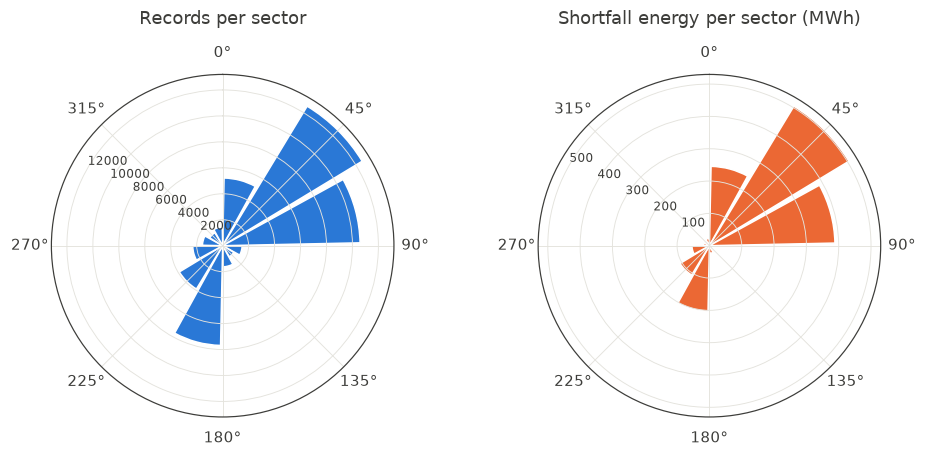

In [17]:
theta = np.deg2rad(rose.index + DIR_SECTOR / 2)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), subplot_kw={"projection": "polar"})
panels = [("records", "Records per sector", "#2a78d6"),
          ("shortfall_mwh", "Shortfall energy per sector (MWh)", "#eb6834")]
for ax, (col, title, color) in zip(axes, panels):
    ax.bar(theta, rose[col], width=np.deg2rad(DIR_SECTOR) * 0.92, color=color, edgecolor="white", linewidth=1)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(300)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(title, pad=14, color=INK)
save_fig(fig, "fig4-1_wind_rose.png")

### C4. Wind-speed bins and time features (reporting only)

In [18]:
df["ws_bin"] = (df.wind_speed // WS_BIN * WS_BIN).round(1)
df["month"] = df.timestamp.dt.month
df["month_name"] = df.timestamp.dt.strftime("%b")
df["hour"] = df.timestamp.dt.hour

### C5. Rule-based reference state (not a label)

The data has no fault labels. These physical rules give a reference for checking whether each cluster makes sense; they are never used as training labels.

| rule_state | Condition |
|---|---|
| `below_operating_range` | wind < operating threshold |
| `zero_output` | wind ≥ threshold **and** power ≤ 0 (shutdown-like) |
| `underperforming` | power ratio < 0.80 |
| `near_curve` | everything else |

**Known limits:** the flat band at ~3,450 kW above ~13 m/s looks like curtailment, but its ratio (~0.96) keeps it in `near_curve`, and the rules cannot tell curtailment from degradation inside `underperforming`.

In [19]:
df["rule_state"] = np.select(
    [~df.in_operating_region, df.power_kw <= 0, df.power_ratio < UNDERPERF_RATIO],
    ["below_operating_range", "zero_output", "underperforming"],
    default="near_curve",
)

state_tbl = df.groupby("rule_state").agg(records=("power_kw", "size"), shortfall_mwh=("shortfall_kwh", "sum"))
state_tbl["shortfall_mwh"] /= 1000
state_tbl["hours"] = state_tbl.records * INTERVAL_H
state_tbl["share_of_shortfall_%"] = 100 * state_tbl.shortfall_mwh / state_tbl.shortfall_mwh.sum()
state_tbl.sort_values("shortfall_mwh", ascending=False)

,records,shortfall_mwh,hours,share_of_shortfall_%
rule_state,,,,
near_curve,31197,700.226,"5,199.500",43.764
zero_output,2220,456.134,370.000,28.508
underperforming,7218,436.014,"1,203.000",27.251
below_operating_range,9895,7.619,"1,649.167",0.476


**Check on the curtailment-like plateau.** Above rated wind speed, a band of records sits just below rated power but still counts as `near_curve`.

In [20]:
rated_wind = df[df.wind_speed >= RATED_WS]
plateau = rated_wind[rated_wind.power_kw.between(3400, 3500)]
print(f"Records at {RATED_WS:.0f} m/s or more: {len(rated_wind):,}; "
      f"{len(plateau):,} ({len(plateau) / len(rated_wind):.0%}) sit between 3,400 and 3,500 kW")
print(f"Plateau median power: {plateau.power_kw.median():,.0f} kW | median power ratio: "
      f"{plateau.power_ratio.median():.2f} | rule states: {plateau.rule_state.value_counts().to_dict()}")

Records at 13 m/s or more: 5,454; 827 (15%) sit between 3,400 and 3,500 kW
Plateau median power: 3,462 kW | median power ratio: 0.96 | rule states: {'near_curve': 827}


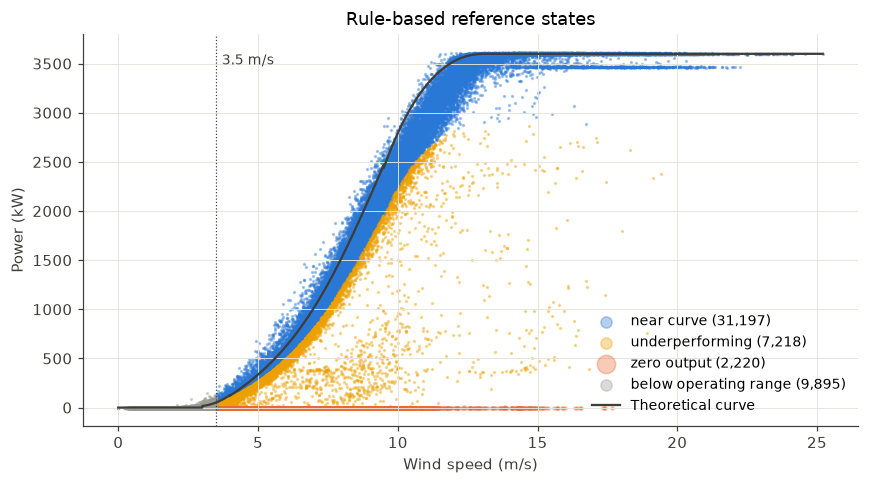

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for state, color in STATE_COLORS.items():
    d = df[df.rule_state == state]
    ax.scatter(d.wind_speed, d.power_kw, s=4 if state == "zero_output" else 1.5, alpha=0.35, color=color,
               label=f"{state.replace('_', ' ')} ({len(d):,})", rasterized=True)
ax.plot(curve.wind_speed, curve.theo_power_kw, color=INK, lw=1.5, label="Theoretical curve")
ax.axvline(OPERATING_WS, color=INK, lw=0.8, ls=":")
ax.text(OPERATING_WS + 0.2, RATED_KW * 0.97, f"{OPERATING_WS} m/s", fontsize=9, color=INK)
ax.set(xlabel="Wind speed (m/s)", ylabel="Power (kW)", title="Rule-based reference states")
ax.legend(loc="lower right", frameon=False, markerscale=6, fontsize=9)
save_fig(fig, "fig4-2_rule_states.png")

### C6. Feature dictionary

In [22]:
feat_dict = pd.DataFrame([
    ("wind_speed", "Original", "Main driver of power output", "Clustering + regression input"),
    ("power_kw", "Original", "Actual output — the quantity we judge", "Clustering input; regression TARGET"),
    ("theo_power_kw", "Original", "Manufacturer expectation", "Reference only (never a regression input)"),
    ("wind_dir", "Original", "Bearing the wind comes from", "Replaced by wd_sin / wd_cos in models"),
    ("power_ratio", "Engineered", "Scale-free closeness to curve; separates stop / curtail / normal", "Clustering input"),
    ("residual_kw", "Engineered", "Size of the gap in kW; large at high wind when output is lost", "Clustering input"),
    ("wd_sin, wd_cos", "Engineered", "Circular encoding so 359° ≈ 1°", "Regression input; optional clustering input"),
    ("dir_sector", "Engineered", "30° sectors for loss-by-direction tables", "Reporting only"),
    ("ws_bin", "Engineered", "0.5 m/s bins (IEC power-curve practice)", "Reporting only"),
    ("month, hour", "Engineered", "When losses happen; month = CV block", "Reporting + CV groups only (leakage risk as inputs)"),
    ("in_operating_region", "Engineered flag", f"wind ≥ {OPERATING_WS} m/s", "Selects clustering subset"),
    ("rule_state", "Engineered flag", "Physical-rule reference state", "Cluster sanity check, not a label"),
    ("actual_kwh, theo_kwh, shortfall_kwh", "Engineered", "Energy per 10-min record (kW × 1/6 h)", "Loss quantification"),
    ("gap_before_min", "Engineered flag", "Minutes since previous record", "Documents missing intervals"),
], columns=["feature", "type", "reason", "role"])
feat_dict

,feature,type,reason,role
0,wind_speed,Original,Main driver of power output,Clustering + regression input
1,power_kw,Original,Actual output — the quantity we judge,Clustering input; regression TARGET
2,theo_power_kw,Original,Manufacturer expectation,Reference only (never a regression input)
3,wind_dir,Original,Bearing the wind comes from,Replaced by wd_sin / wd_cos in models
4,power_ratio,Engineered,Scale-free closeness to curve; separates stop ...,Clustering input
5,residual_kw,Engineered,Size of the gap in kW; large at high wind when...,Clustering input
6,"wd_sin, wd_cos",Engineered,Circular encoding so 359° ≈ 1°,Regression input; optional clustering input
7,dir_sector,Engineered,30° sectors for loss-by-direction tables,Reporting only
8,ws_bin,Engineered,0.5 m/s bins (IEC power-curve practice),Reporting only
9,"month, hour",Engineered,When losses happen; month = CV block,Reporting + CV groups only (leakage risk as in...


## D. Model-ready outputs

**Clustering input:** operating region only, features `wind_speed, power_kw, power_ratio, residual_kw` standardised with `StandardScaler` (K-Means and DBSCAN are distance-based). `wd_sin` and `wd_cos` already lie in [−1, 1] and are added unscaled for the with/without-direction test. Clustering has no train/test split, so the scaler is fitted on the whole subset.

**Regression input:** `wind_speed, wd_sin, wd_cos` → `power_kw`, unscaled (tree models), with `month` as the cross-validation group.

In [23]:
CLUSTER_FEATS = ["wind_speed", "power_kw", "power_ratio", "residual_kw"]
DIRECTION_FEATS = ["wd_sin", "wd_cos"]

clus = df.loc[df.in_operating_region]
assert clus[CLUSTER_FEATS + DIRECTION_FEATS].notna().all().all(), "NaNs in clustering features"

scaler = StandardScaler().fit(clus[CLUSTER_FEATS])
scaled = pd.DataFrame(scaler.transform(clus[CLUSTER_FEATS]),
                      columns=[f"{c}_z" for c in CLUSTER_FEATS], index=clus.index)
cluster_input = pd.concat([clus[["timestamp"]], scaled, clus[DIRECTION_FEATS]], axis=1)
print("Clustering rows:", len(cluster_input))
cluster_input.describe().T[["mean", "std", "min", "max"]]

Clustering rows: 40635


,mean,std,min,max
timestamp,2018-07-04 14:42:50.468807,NaN,2018-01-01 00:00:00,2018-12-31 23:50:00
wind_speed_z,0.000,1.000,-1.454,4.445
power_kw_z,-0.000,1.000,-1.275,1.563
power_ratio_z,0.000,1.000,-3.218,2.567
residual_kw_z,-0.000,1.000,-1.774,7.229
wd_sin,0.308,0.626,-1.000,1.000
wd_cos,0.117,0.706,-1.000,1.000


In [24]:
OUT_COLS = ["timestamp", "month", "month_name", "hour", "gap_before_min",
            "wind_speed", "ws_bin", "wind_dir", "wd_sin", "wd_cos", "dir_sector", "dir_sector_start",
            "power_kw", "theo_power_kw", "power_ratio", "residual_kw",
            "actual_kwh", "theo_kwh", "shortfall_kwh", "in_operating_region", "rule_state"]
df[OUT_COLS].to_csv(OUT_DIR / "wind_features.csv", index=False)
cluster_input.to_csv(OUT_DIR / "cluster_input_scaled.csv", index_label="row_id")
joblib.dump({"scaler": scaler, "features": CLUSTER_FEATS}, OUT_DIR / "cluster_scaler.joblib")
dq.to_csv(OUT_DIR / "data_quality_summary.csv", index=False)
feat_dict.to_csv(OUT_DIR / "feature_dictionary.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

Saved:
  cluster_input_scaled.csv
  cluster_scaler.joblib
  data_quality_summary.csv
  feature_dictionary.csv
  wind_features.csv
